**Part 1:**

In [2]:
import pandas as pd

df = pd.read_csv("/class1_student_habits.csv")

df.head()

,student_id,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,quiz_average,exam_score
0,S001,1.3,7.7,71.8,8,Strong,No,0,67.0,64.6
1,S002,9.4,6.6,74.2,14,NaN,Yes,52,74.8,81.5
2,S003,11.2,6.1,70.3,15,Some,No,7,99.1,92.0
3,S004,10.8,7.6,77.1,16,Strong,No,12,86.4,100.0
4,S005,8.0,5.6,89.7,15,NaN,Yes,12,75.7,68.5


1. What is a Pandas DataFrame?
- A Pandas DataFrame is a way of storing data in a table made up of rows and columns, similar to an Excel spreadsheet.

2. What does one row represent in this dataset?
- Each row represents an individual student and contains information about that student's habits and academic performance.

3. What does one column represent?
- Each column represents a specific type of information about the students, such as weekly study hours, attendance rate, or exam score.

**Part 2:**

In [3]:
# Number of rows and columns
print("Rows and columns:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns)

# Data types
print("\nData types:")
print(df.dtypes)

# Missing values in each column
print("\nMissing values:")
print(df.isna().sum())

Rows and columns: (250, 10)

Column names:
Index(['student_id', 'study_hours_per_week', 'sleep_hours_per_night',
       'attendance_rate', 'practice_problems_per_week',
       'prior_programming_experience', 'study_group', 'commute_minutes',
       'quiz_average', 'exam_score'],
      dtype='object')

Data types:
student_id                       object
study_hours_per_week            float64
sleep_hours_per_night           float64
attendance_rate                 float64
practice_problems_per_week        int64
prior_programming_experience     object
study_group                      object
commute_minutes                   int64
quiz_average                    float64
exam_score                      float64
dtype: object

Missing values:
student_id                       0
study_hours_per_week             9
sleep_hours_per_night           12
attendance_rate                  0
practice_problems_per_week       0
prior_programming_experience    95
study_group                      0
commute_m

1. Which columns are numerical?
- The numerical columns are study_hours_per_week, sleep_hours_per_night, attendance_rate, practice_problems_per_week, commute_minutes, quiz_average, and exam_score.

2. Which columns are categorical?
- The categorical columns are prior_programming_experience and study_group.

3. Which column is an identifier?
- The student_id column is the identifier because it is used to distinguish each student rather than describe a measured characteristic.

4. Which columns contain missing values?
- The columns with missing values are study_hours_per_week with 9 missing values, sleep_hours_per_night with 12 missing values, and prior_programming_experience with 95 missing values. All other columns have no missing values.

**Part 3:**

In [4]:
columns = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "commute_minutes",
    "quiz_average",
    "exam_score"
]

statistics = df[columns].agg(["count", "mean", "median", "std", "min", "max"])

statistics

,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,commute_minutes,quiz_average,exam_score
count,241.000000,238.000000,250.000000,250.00000,250.000000,250.000000,250.000000
mean,7.500830,7.004622,85.468800,16.85600,24.428000,77.774400,77.159600
median,7.500000,7.100000,85.750000,16.00000,23.000000,77.100000,76.950000
std,2.937544,1.042605,9.578326,9.56122,18.110682,10.515014,10.330499
min,0.300000,4.300000,54.400000,0.00000,0.000000,49.300000,51.400000
max,17.800000,10.000000,100.000000,78.00000,145.000000,100.000000,100.000000


**Three interesting observations:**

- Students in this dataset studied about 7.5 hours per week on average. Since the mean and median are almost the same, study time appears to be fairly balanced around that value rather than being heavily affected by a few unusually high or low values.

- Attendance was generally high, with students averaging about 85% attendance. However, attendance still varied quite a bit, ranging from 54.4% to 100%, which shows that some students attended much more consistently than others.

- Exam scores were centered around the upper 70s, with both the mean and median close to 77. The scores ranged from 51.4 to 100, so there was a noticeable difference between the lowest- and highest-performing students.

**Part 4:**

In [5]:
## Part A ##

filtered_students = df[
    (df["study_hours_per_week"] >= 10) &
    (df["attendance_rate"] >= 90)
]

filtered_students[
    ["student_id", "study_hours_per_week", "attendance_rate", "exam_score"]
]


,student_id,study_hours_per_week,attendance_rate,exam_score
9,S010,11.7,91.0,70.5
10,S011,11.1,94.5,75.9
22,S023,10.5,93.6,79.9
41,S042,10.7,98.2,96.2
54,S055,11.4,100.0,77.1
63,S064,11.7,94.6,94.1
108,S109,10.1,91.6,100.0
119,S120,11.0,90.7,98.8
167,S168,11.8,100.0,97.2
168,S169,12.3,93.2,96.8


The filtered results show 16 students who studied at least 10 hours per week and had an attendance rate of at least 90%. Their exam scores vary quite a bit, from the mid-60s up to 100. This shows that even among students with relatively high study time and attendance, exam performance was not exactly the same for everyone.


In [6]:
## Part B ##

top_exam_scores = df.sort_values(
    by="exam_score",
    ascending=False
).head(10)

top_exam_scores[
    [
        "student_id",
        "exam_score",
        "quiz_average",
        "study_hours_per_week",
        "attendance_rate",
        "practice_problems_per_week"
    ]
]

,student_id,exam_score,quiz_average,study_hours_per_week,attendance_rate,practice_problems_per_week
3,S004,100.0,86.4,10.8,77.1,16
108,S109,100.0,94.1,10.1,91.6,25
223,S224,100.0,83.4,16.2,84.7,13
215,S216,99.0,96.4,9.0,100.0,15
119,S120,98.8,95.0,11.0,90.7,8
143,S144,97.5,88.1,9.1,96.6,16
167,S168,97.2,98.3,11.8,100.0,19
168,S169,96.8,94.1,12.3,93.2,21
139,S140,96.6,92.3,7.3,100.0,31
231,S232,96.5,84.5,5.1,93.4,15


The 10 highest exam scores range from 96.5 to 100. Several of these students also had high quiz averages and strong attendance, although not every top-scoring student studied more than 10 hours per week. For example, some students in the top 10 studied fewer than 10 hours but still earned very high exam scores.

In [ ]:
## Part C ##

In [7]:
study_group_comparison = df.groupby("study_group")["exam_score"].agg(
    ["count", "mean", "median"]
)

study_group_comparison

,count,mean,median
study_group,,,
No,121,76.871074,75.9
Yes,129,77.430233,77.7


There were 121 students who did not participate in a study group and 129 students who did. Students who participated in a study group had a slightly higher mean exam score, about 77.4 compared with about 76.9 for students who did not participate. Their median exam score was also slightly higher, 77.7 compared with 75.9.

What do you observe from the group comparison?

- The difference between the groups is fairly small, so the results suggest only a slight association between study-group participation and exam scores in this dataset. They do not prove that participating in a study group caused higher exam scores.

**Part 5:**

In [8]:
import matplotlib.pyplot as plt

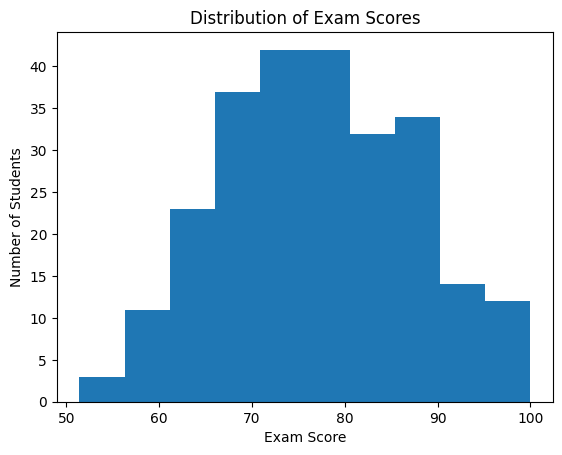

In [9]:
## Part 1 ##

plt.hist(df["exam_score"])

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.show()

Most exam scores are concentrated roughly between 65 and 90. The highest concentration appears to be around the 70s, while relatively few students scored near the lowest end of the range or close to 100. Overall, the scores are fairly spread out but centered around the upper 70s.

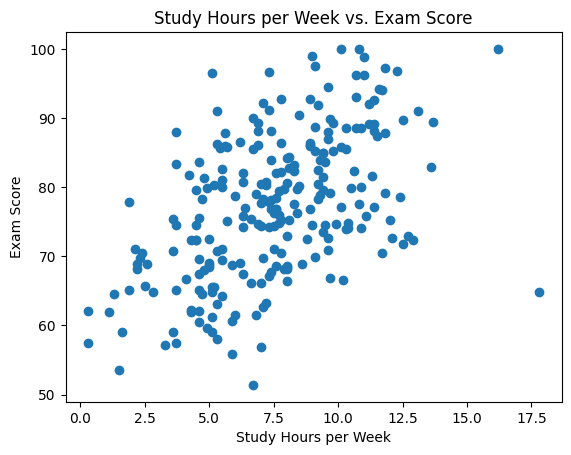

In [10]:
## Part 2 ##

plt.scatter(df["study_hours_per_week"], df["exam_score"])

plt.title("Study Hours per Week vs. Exam Score")
plt.xlabel("Study Hours per Week")
plt.ylabel("Exam Score")

plt.show()

The scatter plot shows a general upward trend, where students who study more hours per week often have higher exam scores. However, the points are spread out, so students with similar study times can still have very different exam scores. This suggests that study time is associated with exam performance, but it is not the only factor related to the score.

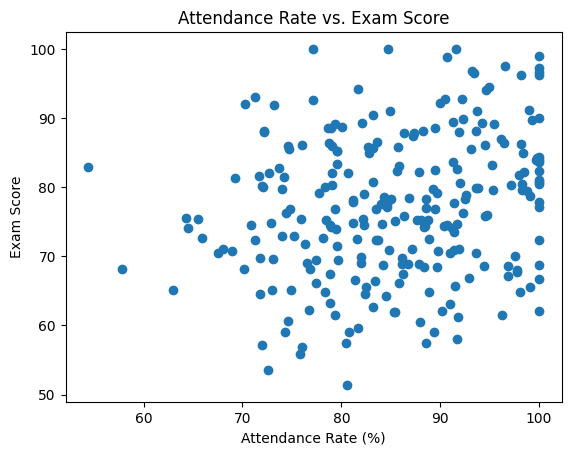

In [11]:
## Part 3 ##

plt.scatter(df["attendance_rate"], df["exam_score"])

plt.title("Attendance Rate vs. Exam Score")
plt.xlabel("Attendance Rate (%)")
plt.ylabel("Exam Score")

plt.show()

Students with higher attendance rates appear across a wide range of exam scores, but higher scores are more common among students with stronger attendance. The points are fairly scattered, so the relationship does not appear especially strong. This suggests some association between attendance and exam score, while still showing a lot of variation between students.

**Part 6:**

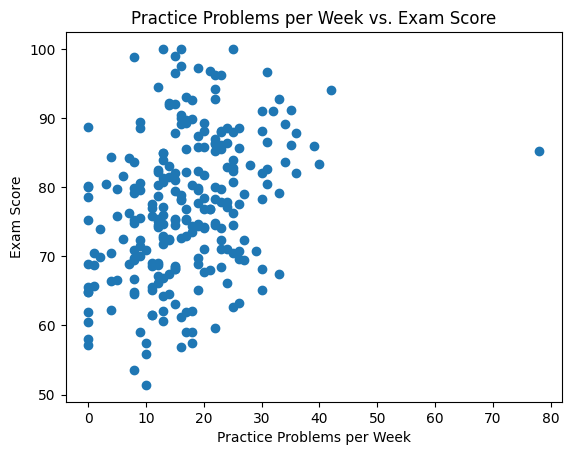

In [13]:
## Relationship betweeen practice_problems_per_week and exam_score ##

plt.scatter(df["practice_problems_per_week"], df["exam_score"])

plt.title("Practice Problems per Week vs. Exam Score")
plt.xlabel("Practice Problems per Week")
plt.ylabel("Exam Score")

plt.show()

In [14]:
## Calculate correlation ##

correlation = df["practice_problems_per_week"].corr(df["exam_score"])

print("Correlation:", correlation)

Correlation: 0.3370722204795144


Prediction

- I expect the number of practice problems completed per week to be positively associated with exam score because students who practice more may be more familiar with the material and types of problems covered on the exam.

Correlation

- The correlation between practice_problems_per_week and exam_score is approximately 0.34. This is a positive correlation, meaning that students who completed more practice problems tended to have higher exam scores. However, the relationship is not very strong because the points in the scatter plot are fairly spread out. This result shows an association between practice problems and exam scores in this dataset, but it does not prove that completing more practice problems directly causes higher exam scores.

**Part 7**

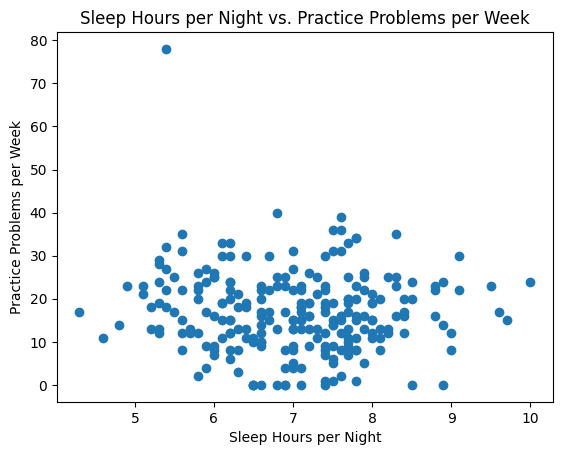

In [15]:
## Do students who get more sleep tend to complete more practice problems per week? ##

plt.scatter(df["sleep_hours_per_night"], df["practice_problems_per_week"])

plt.title("Sleep Hours per Night vs. Practice Problems per Week")
plt.xlabel("Sleep Hours per Night")
plt.ylabel("Practice Problems per Week")

plt.show()

In [17]:
## Calculate the correlation ##

correlation = df["sleep_hours_per_night"].corr(
    df["practice_problems_per_week"]
)

print("Correlation:", correlation)

Correlation: -0.07860986437192743


### Question

Do students who get more sleep tend to complete more practice problems per week?

### Analysis

I compared `sleep_hours_per_night` with `practice_problems_per_week` using a scatter plot and calculated the correlation between the two variables. The scatter plot shows that the points are spread out without a clear upward or downward pattern.

The correlation is approximately **-0.08**, which is very close to zero. This indicates that there is little to no linear relationship between sleep hours and the number of practice problems completed per week in this dataset.

### Conclusion

Based on this analysis, students who get more sleep do not appear to consistently complete more practice problems per week. The very weak negative correlation suggests that sleep duration and practice-problem completion are mostly unrelated in this dataset.

### AI Refleciton

During this assignment, I used AI as a guide while working through the different parts of the data analysis. It helped me understand how to use Pandas and Matplotlib, suggested appropriate visualizations, and explained what some of the code was doing. One example was when I investigated the relationship between practice problems per week and exam score. AI suggested using a scatter plot and correlation, then explained how the correlation value should be interpreted without treating it as proof of causation.

I also used AI when I ran into problems or was unsure whether I was using the correct approach. For example, when my CSV file was not loading in Google Colab, I checked the error and fixed the issue by uploading the file into the Colab environment. For the analysis itself, I verified the AI’s suggestions by running the code myself, looking at the actual outputs, checking the graphs, and making sure the columns matched the question I was trying to answer. I also compared the visual patterns with the numerical results, such as the correlation values, to make sure the interpretation made sense.

One thing I learned from this assignment was how useful correlation can be for describing the direction and strength of a relationship between two numerical variables. I also learned that a relationship in the data does not automatically mean that one variable caused the other. Another thing I became more comfortable with was using Pandas to filter, sort, group, and summarize data instead of only looking at the raw dataset.

